In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
df = pd.read_excel(
    "D:/KHDL TRONG MKT/OnlineRetail.xlsx", 
    engine='openpyxl', 
    parse_dates=["InvoiceDate"]
)
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [29]:
df = df.dropna(subset=["CustomerID"])
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [30]:
print(df[df['Quantity'] < 0].head())
df = df[df['Quantity'] > 0]
print(df[df['UnitPrice'] <= 0].head())
df = df[df['UnitPrice'] > 0]
print("\nThông tin tập dữ liệu đầy đủ sau khi làm sạch:")
df.info()


    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom      -27.50  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom       -4.65  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom      -19.80  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom       -6.96  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom       -6.96  
      InvoiceNo StockCode                   Description  Quantity  \
9302     537197     22841  ROUND CAKE TIN 

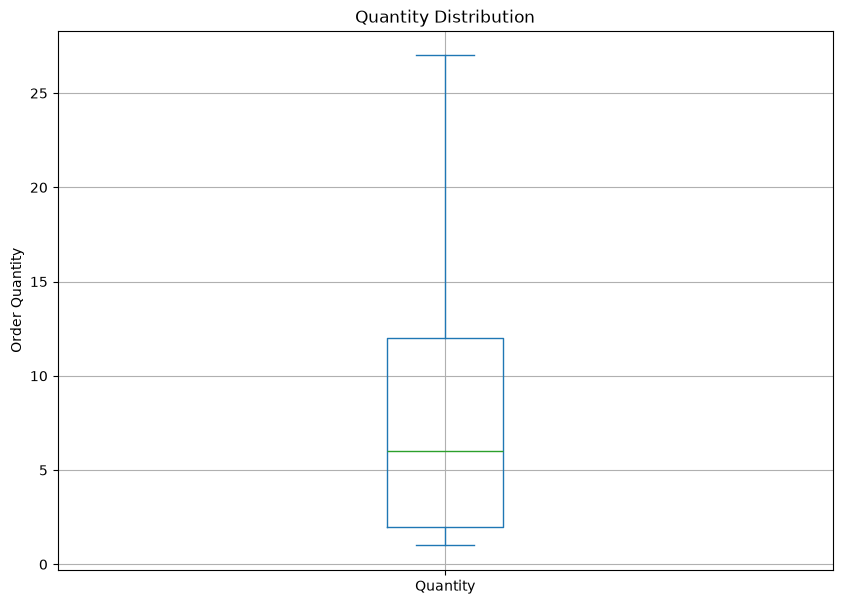

In [31]:
ax = df['Quantity'].plot.box(showfliers=False,
                             grid=True,
                             figsize=(10, 7)) 
ax.set_ylabel('Order Quantity')
ax.set_title('Quantity Distribution')
plt.suptitle("")
plt.show()

In [32]:
monthly_orders_df = df.set_index('InvoiceDate')['InvoiceNo'].resample('ME').nunique()
monthly_orders_df

InvoiceDate
2010-12-31    1400
2011-01-31     987
2011-02-28     997
2011-03-31    1321
2011-04-30    1149
2011-05-31    1555
2011-06-30    1393
2011-07-31    1331
2011-08-31    1280
2011-09-30    1755
2011-10-31    1929
2011-11-30    2657
2011-12-31     778
Freq: ME, Name: InvoiceNo, dtype: int64

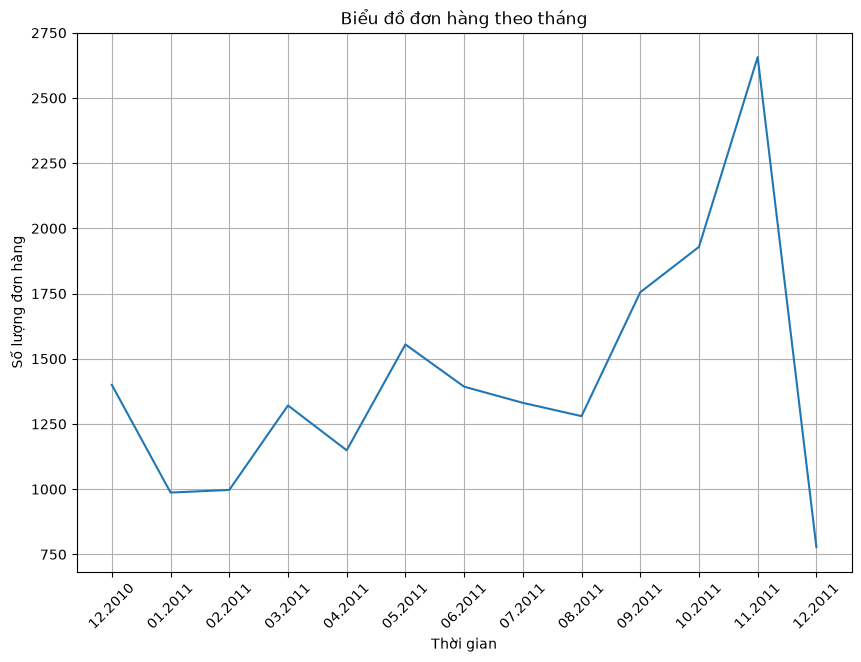

In [33]:
ax = pd.DataFrame(monthly_orders_df.values).plot(grid=True,
                                                 figsize=(10,7),
                                                 legend=False) 
ax.set_xlabel('Thời gian')
ax.set_ylabel('Số lượng đơn hàng')
ax.set_title('Biểu đồ đơn hàng theo tháng')
plt.xticks( range(len(monthly_orders_df.index)),
           [x.strftime('%m.%Y') for x in monthly_orders_df.index],
           rotation=45) 
plt.show()

In [34]:
df['Sales'] = df['Quantity'] * df['UnitPrice']
monthly_revenue_df = df.set_index('InvoiceDate')['Sales'].resample('ME').sum()
monthly_revenue_df

InvoiceDate
2010-12-31     572713.890
2011-01-31     569445.040
2011-02-28     447137.350
2011-03-31     595500.760
2011-04-30     469200.361
2011-05-31     678594.560
2011-06-30     661213.690
2011-07-31     600091.011
2011-08-31     645343.900
2011-09-30     952838.382
2011-10-31    1039318.790
2011-11-30    1161817.380
2011-12-31     518192.790
Freq: ME, Name: Sales, dtype: float64

In [35]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,20.34


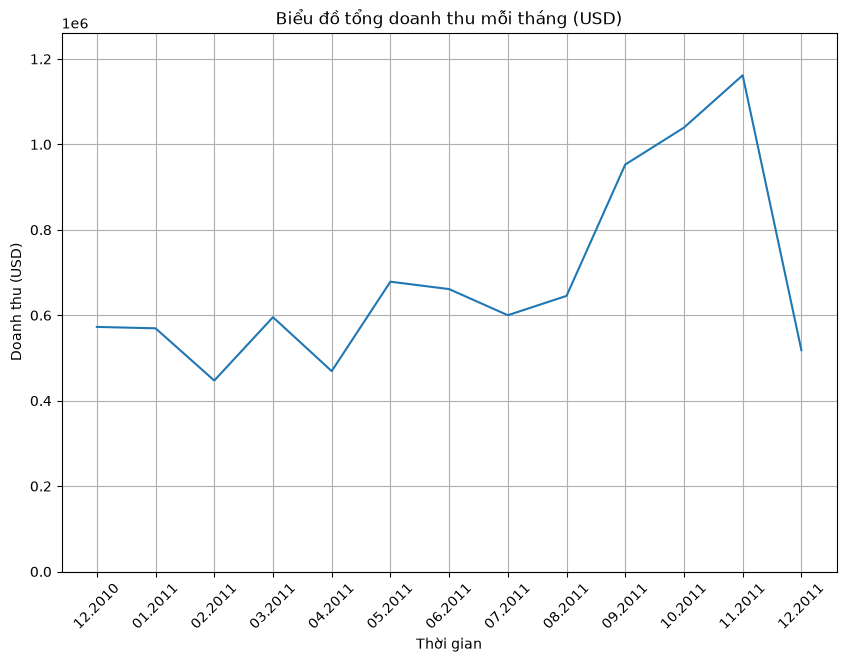

In [36]:
ax = pd.DataFrame(monthly_revenue_df.values).plot(grid=True,
                                                  figsize=(10,7),
                                                  legend=False) 
ax.set_xlabel('Thời gian')
ax.set_ylabel('Doanh thu (USD)')
ax.set_title('Biểu đồ tổng doanh thu mỗi tháng (USD)')
ax.set_ylim([0, max(monthly_revenue_df.values)+100000])
plt.xticks(range(len(monthly_revenue_df.index)),
           [x.strftime('%m.%Y') for x in monthly_revenue_df.index],
           rotation=45) 
plt.show()

In [37]:
df['Country'].nunique()

37

In [38]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')
df['Month'].head()

0    2010-12
1    2010-12
2    2010-12
3    2010-12
4    2010-12
Name: Month, dtype: period[M]

In [39]:
customers_by_month = df.groupby('Month')['CustomerID'].unique()
customers_by_month.head()

Month
2010-12    [17850.0, 13047.0, 12583.0, 13748.0, 15100.0, ...
2011-01    [13313.0, 18097.0, 16656.0, 16875.0, 13094.0, ...
2011-02    [15240.0, 14911.0, 14496.0, 17147.0, 17675.0, ...
2011-03    [14620.0, 14740.0, 13880.0, 16462.0, 17068.0, ...
2011-04    [18161.0, 14886.0, 17613.0, 12523.0, 13694.0, ...
Freq: M, Name: CustomerID, dtype: object

In [40]:
#RETENTION RATE
retained_customers = []

months = customers_by_month.index

for i in range(1, len(months)):
    prev_month_customers = set(customers_by_month[months[i-1]])  
    curr_month_customers = set(customers_by_month[months[i]])    

    retained = prev_month_customers & curr_month_customers
    retention_rate = (len(retained) / len(curr_month_customers) * 100) if len(curr_month_customers) > 0 else 0

    retained_customers.append({
        'Month': str(months[i]),
        'RetainedCustomers': len(retained),
        'CurrMonthCustomers': len(curr_month_customers),
        'RetentionRate(%)': round(retention_rate, 2)
    })

retained_df = pd.DataFrame(retained_customers)
retained_df.head()

,Month,RetainedCustomers,CurrMonthCustomers,RetentionRate(%)
0,2011-01,324,741,43.72
1,2011-02,262,758,34.56
2,2011-03,290,974,29.77
3,2011-04,304,856,35.51
4,2011-05,368,1056,34.85


In [41]:
import pandas as pd

retention_revenue = []

for i in range(1, len(months)):
    prev_month_customers = set(customers_by_month[months[i-1]])
    curr_month_customers = set(customers_by_month[months[i]])
    
    retained_customers = prev_month_customers & curr_month_customers
    
    curr_month_data = df[df['Month'] == months[i]]
    retained_data = curr_month_data[curr_month_data['CustomerID'].isin(retained_customers)]
    
    retained_sales = retained_data['Sales'].sum()
    total_sales = curr_month_data['Sales'].sum()
    
    ratio = (retained_sales / total_sales * 100) if total_sales > 0 else 0

    retention_revenue.append({
        'Month': str(months[i]),
        'RetainedRevenue': retained_sales,  # 2. Sửa returning_sales thành retained_sales
        'TotalRevenue': total_sales,
        'RevenueFromReturning(%)': round(ratio, 2)
    })

revenue_retained_df = pd.DataFrame(retention_revenue)
print(revenue_retained_df)

      Month  RetainedRevenue  TotalRevenue  RevenueFromReturning(%)
0   2011-01        276237.69    569445.040                    48.51
1   2011-02        215663.52    447137.350                    48.23
2   2011-03        275797.81    595500.760                    46.31
3   2011-04        215482.02    469200.361                    45.93
4   2011-05        363280.99    678594.560                    53.53
5   2011-06        378689.76    661213.690                    57.27
6   2011-07        322100.96    600091.011                    53.68
7   2011-08        353658.97    645343.900                    54.80
8   2011-09        526469.93    952838.382                    55.25
9   2011-10        543521.50   1039318.790                    52.30
10  2011-11        642274.35   1161817.380                    55.28
11  2011-12        249715.05    518192.790                    48.19


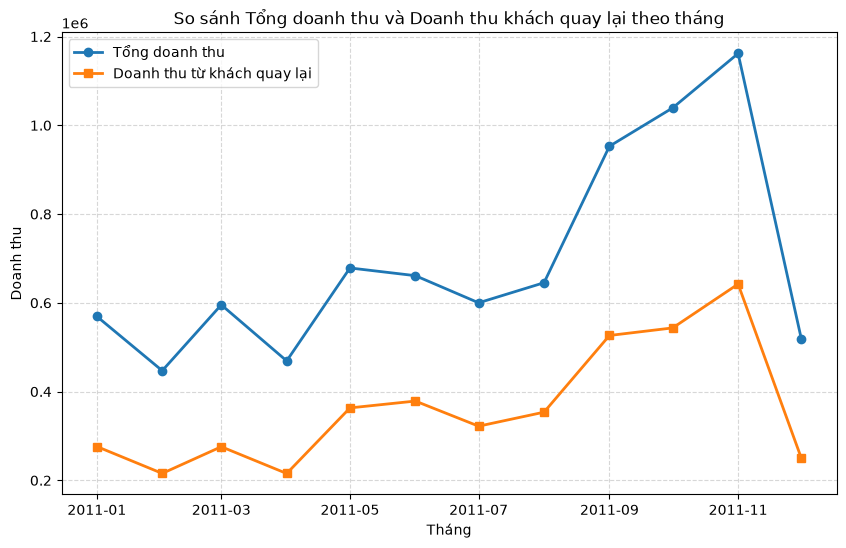

In [42]:
import matplotlib.pyplot as plt

# 1. Chuyển kiểu dữ liệu ngày tháng
revenue_retained_df['Month'] = pd.to_datetime(revenue_retained_df['Month'])

# 2. Vẽ biểu đồ
plt.figure(figsize=(10, 6))

# Đường 1: Tổng doanh thu
plt.plot(
    revenue_retained_df['Month'],
    revenue_retained_df['TotalRevenue'],
    marker='o',
    linewidth=2,
    label='Tổng doanh thu',
)

# Đường 2: Doanh thu từ khách quay lại (Dùng 'RetainedRevenue')
plt.plot(
    revenue_retained_df['Month'],
    revenue_retained_df['RetainedRevenue'],
    marker='s',
    linewidth=2,
    label='Doanh thu từ khách quay lại',
)

plt.title('So sánh Tổng doanh thu và Doanh thu khách quay lại theo tháng', fontsize=12)
plt.xlabel('Tháng', fontsize=10)
plt.ylabel('Doanh thu', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()

In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Đảm bảo cột InvoiceDate ở dạng datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 2. Tạo cột phụ chứa Tháng-Năm (ví dụ: '2011-01', '2011-02') để phân nhóm
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# 3. Chia ngẫu nhiên 80% train và 20% test trong từng tháng
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,          # Đảm bảo kết quả chia tái lập được
    stratify=df['YearMonth']   # Chia đều tỷ lệ 80/20 cho từng tháng
)

# 4. Bỏ cột tạm YearMonth (nếu không cần dùng tiếp)
train_df = train_df.drop(columns=['YearMonth'])
test_df = test_df.drop(columns=['YearMonth'])

# 5. In kiểm tra thông tin
print(f"Kích thước tập train (80%): {train_df.shape[0]} dòng")
print(f"Kích thước tập test (20%): {test_df.shape[0]} dòng")
print(f"Thời gian tập train: từ {train_df['InvoiceDate'].min()} đến {train_df['InvoiceDate'].max()}")
print(f"Thời gian tập test:  từ {test_df['InvoiceDate'].min()} đến {test_df['InvoiceDate'].max()}")

Kích thước tập train (80%): 318307 dòng
Kích thước tập test (20%): 79577 dòng
Thời gian tập train: từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00
Thời gian tập test:  từ 2010-12-01 08:34:00 đến 2011-12-09 12:50:00


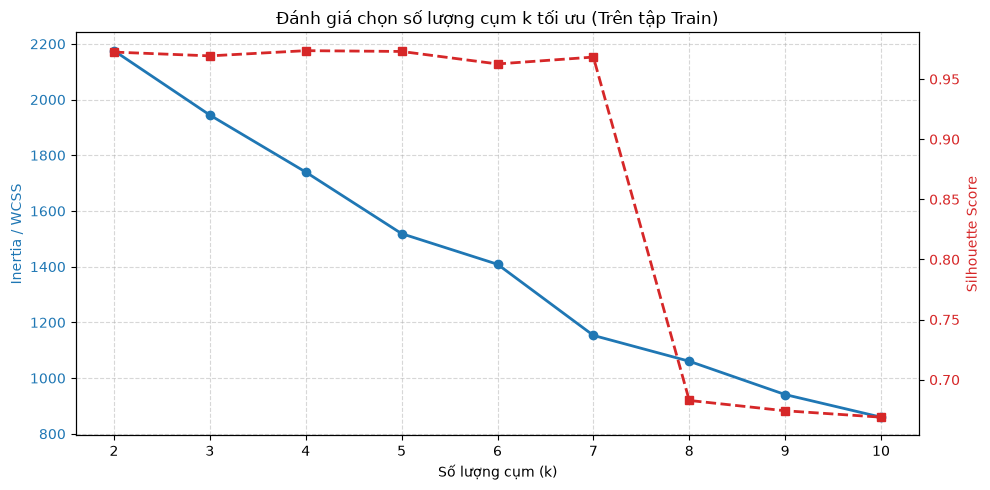

-> Số cụm k tối ưu gợi ý theo Silhouette Score (0.974) là: k = 4


In [ ]:
#USER-BASED
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MaxAbsScaler

train_user_item = train_df.pivot_table(
    index='CustomerID', columns='StockCode', values='Quantity', fill_value=0
)

train_user_item.columns = train_user_item.columns.astype(str)

scaler = MaxAbsScaler()
train_matrix_scaled = scaler.fit_transform(train_user_item)

svd = TruncatedSVD(n_components=min(20, train_matrix_scaled.shape[1] - 1), random_state=42)
train_matrix_reduced = svd.fit_transform(train_matrix_scaled)

k_range = range(2, 11)
wcss = []
silhouette_scores = []

for k in k_range:
    kmeans_train = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_train.fit_predict(train_matrix_reduced)

    wcss.append(kmeans_train.inertia_)
    silhouette_scores.append(silhouette_score(train_matrix_reduced, labels))

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Số lượng cụm (k)')
ax1.set_ylabel('Inertia / WCSS', color=color)
ax1.plot(k_range, wcss, marker='o', color=color, linewidth=2, label='WCSS')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(
    k_range,
    silhouette_scores,
    marker='s',
    color=color,
    linewidth=2,
    linestyle='--',
    label='Silhouette',
)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Đánh giá chọn số lượng cụm k tối ưu (Trên tập Train)')
fig.tight_layout()
plt.show()

# 6. In số cụm tối ưu
best_k = k_range[np.argmax(silhouette_scores)]
print(
    f'-> Số cụm k tối ưu gợi ý theo Silhouette Score ({max(silhouette_scores):.3f}) là: k = {best_k}'
)

In [45]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

customer_product_matrix = train_df.pivot_table(
    index='CustomerID',
    columns='Description',
    values='Quantity',
    aggfunc='sum',
    fill_value=0,
)

customer_product_matrix.columns = customer_product_matrix.columns.astype(str)

scaler = StandardScaler()
matrix_scaled = scaler.fit_transform(customer_product_matrix)

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
customer_clusters = kmeans.fit_predict(matrix_scaled)

customer_product_matrix['Cluster'] = customer_clusters

print("Danh sách CustomerID tập Train:")
print(customer_product_matrix.index)

print("\nSố lượng khách hàng trong từng cụm (Tập Train):")
print(customer_product_matrix['Cluster'].value_counts().sort_index())

Danh sách CustomerID tập Train:
Index([12346.0, 12347.0, 12348.0, 12349.0, 12350.0, 12352.0, 12353.0, 12354.0,
       12355.0, 12356.0,
       ...
       18273.0, 18274.0, 18276.0, 18277.0, 18278.0, 18280.0, 18281.0, 18282.0,
       18283.0, 18287.0],
      dtype='float64', name='CustomerID', length=4316)

Số lượng khách hàng trong từng cụm (Tập Train):
Cluster
0    4312
1       2
2       1
3       1
Name: count, dtype: int64


In [46]:

try:
    target_customer = int(float(input("Nhập ID khách hàng: ")))
except ValueError:
    print("[Lỗi] ID khách hàng phải là một số hợp lệ.")
    target_customer = None

if target_customer is not None:

    if target_customer in customer_product_matrix.index:

        target_cluster = customer_product_matrix.loc[target_customer, 'Cluster']

        same_cluster_mask = (customer_product_matrix['Cluster'] == target_cluster) & (customer_product_matrix.index != target_customer)
        same_cluster_customers = customer_product_matrix.loc[same_cluster_mask]

        cluster_product_sums = same_cluster_customers.drop(columns='Cluster').sum()

        customer_profile = customer_product_matrix.loc[target_customer].drop('Cluster')
        products_bought = set(customer_profile[customer_profile > 0].index)

        unbought_products = cluster_product_sums.drop(labels=products_bought, errors='ignore')
        top_recommendations = unbought_products.sort_values(ascending=False).head(5)

        print(f"\n--- KẾT QUẢ GỢI Ý CHO KHÁCH HÀNG ID [{target_customer}] ---")
        print(f"Khách hàng thuộc Cluster: {target_cluster}")
        print(f"Top {len(top_recommendations)} sản phẩm gợi ý hàng đầu:")
        for rank, (prod_name, total_qty) in enumerate(top_recommendations.items(), start=1):
            print(f"  {rank}. {prod_name} (Tổng lượt mua trong cụm: {int(total_qty)})")

    elif 'test_df' in locals() and target_customer in test_df['CustomerID'].values:
        print(f"\n[Thông báo] Khách hàng ID {target_customer} chỉ xuất hiện trong tập TEST (Khách hàng mới/Cold Start).")
        print("Gợi ý các sản phẩm bán chạy nhất toàn hệ thống (Popularity-based):")
      
        top_popular = customer_product_matrix.drop(columns='Cluster').sum().sort_values(ascending=False).head(5)
        for rank, (prod_name, total_qty) in enumerate(top_popular.items(), start=1):
            print(f"  {rank}. {prod_name}")
            
    else:
        print(f"\n[Lỗi] Khách hàng ID {target_customer} không tồn tại trong hệ thống.")


--- KẾT QUẢ GỢI Ý CHO KHÁCH HÀNG ID [13047] ---
Khách hàng thuộc Cluster: 0
Top 5 sản phẩm gợi ý hàng đầu:
  1. PAPER CRAFT , LITTLE BIRDIE (Tổng lượt mua trong cụm: 80995)
  2. MEDIUM CERAMIC TOP STORAGE JAR (Tổng lượt mua trong cụm: 77228)
  3. WORLD WAR 2 GLIDERS ASSTD DESIGNS (Tổng lượt mua trong cụm: 43712)
  4. JUMBO BAG RED RETROSPOT (Tổng lượt mua trong cụm: 34748)
  5. ASSORTED COLOUR BIRD ORNAMENT (Tổng lượt mua trong cụm: 28624)


In [ ]:
#APRIORI
import pandas as pd
from itertools import combinations
from collections import defaultdict, Counter
train_df = train_df.dropna(subset=['CustomerID', 'InvoiceDate'])

if 'Sales' not in train_df.columns:
    train_df['Sales'] = train_df['Quantity'] * train_df['UnitPrice']

train_df['BasketID'] = (
    train_df['CustomerID'].astype(str) + '_' + train_df['InvoiceDate'].astype(str)
)

print("Danh sách các cột trong train_df:", train_df.columns.tolist())

train_positive = train_df[train_df['Quantity'] > 0]

basket_items = train_positive.groupby('BasketID')['StockCode'].unique()

num_baskets = len(basket_items)
print(f"Tổng số giỏ hàng trong train_df: {num_baskets}")

pair_counts = defaultdict(int)
item_counter = Counter()

for basket_id, items in basket_items.items():
    items_str = sorted(list(set(str(item) for item in items)))

    for item in items_str:
        item_counter[item] += 1

    for pair in combinations(items_str, 2):
        pair_counts[pair] += 1

pair_df = pd.DataFrame([
    {'ItemA': a, 'ItemB': b, 'Frequency': freq}
    for (a, b), freq in pair_counts.items()
])

min_freq = 0.01 * num_baskets  
filtered_pairs = pair_df[pair_df['Frequency'] >= min_freq]

print(f"Tổng số cặp sản phẩm xuất hiện: {len(pair_df)}")
print(f"Số cặp sản phẩm xuất hiện >= 1% số giỏ hàng: {len(filtered_pairs)}")

rules = []
for _, row in filtered_pairs.iterrows():
    a, b, freq_ab = row['ItemA'], row['ItemB'], row['Frequency']
    
    support = freq_ab / num_baskets
    conf_ab = freq_ab / item_counter[a]
    conf_ba = freq_ab / item_counter[b]
    lift_ab = conf_ab / (item_counter[b] / num_baskets)
    lift_ba = conf_ba / (item_counter[a] / num_baskets)

    rules.append({
        'ItemA': a,
        'ItemB': b,
        'Support': round(support, 4),
        'Confidence(A→B)': round(conf_ab, 4),
        'Confidence(B→A)': round(conf_ba, 4),
        'Lift(A→B)': round(lift_ab, 4),
        'Lift(B→A)': round(lift_ba, 4),
        'Frequency': freq_ab
    })

rules_df = pd.DataFrame(rules)

if not rules_df.empty:
    rules_df = rules_df.sort_values(by='Lift(A→B)', ascending=False)
    rules_df = rules_df[rules_df['Lift(A→B)'] >= 1]

    rules_df.to_excel("Association_Rules_Train.xlsx", index=False)
    print("Đã xuất tập luật Apriori thành công vào file 'Association_Rules_Train.xlsx'!")
    print(rules_df.head())
else:
    print("Không có luật nào đạt ngưỡng lọc.")

Danh sách các cột trong train_df: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'Sales', 'Month', 'BasketID']
Tổng số giỏ hàng trong train_df: 18119
Tổng số cặp sản phẩm xuất hiện: 1840490
Số cặp sản phẩm xuất hiện >= 1% số giỏ hàng: 104
Đã xuất tập luật Apriori thành công vào file 'Association_Rules_Train.xlsx'!
     ItemA  ItemB  Support  Confidence(A→B)  Confidence(B→A)  Lift(A→B)  \
92   22577  22578   0.0119           0.5714           0.6207    29.7521   
6    22697  22698   0.0173           0.5451           0.6871    21.6135   
102  22865  22866   0.0101           0.3978           0.4906    19.3250   
90   82483  82486   0.0101           0.4420           0.4159    18.2026   
10   22629  22630   0.0152           0.4800           0.5774    18.1948   

     Lift(B→A)  Frequency  
92     29.7521        216  
6      21.6135        314  
102    19.3250        183  
90     18.2026        183  
10     18.1948     

In [48]:
try:
    target_customer = int(float(input("Nhập Customer ID: ")))
except ValueError:
    print("[Lỗi] ID khách hàng nhập vào không hợp lệ!")
    target_customer = None

if target_customer is not None:
    
    if target_customer in customer_product_matrix.index:

        target_cluster = customer_product_matrix.loc[
            target_customer, 'Cluster'
        ]

        same_cluster_mask = (
            customer_product_matrix['Cluster'] == target_cluster
        ) & (customer_product_matrix.index != target_customer)
        same_cluster_customers = customer_product_matrix.loc[same_cluster_mask]

        cluster_product_sums = same_cluster_customers.drop(
            columns='Cluster'
        ).sum()

        customer_profile = customer_product_matrix.loc[target_customer].drop(
            'Cluster'
        )
        products_bought = set(customer_profile[customer_profile > 0].index)

        unbought_products = cluster_product_sums.drop(
            labels=products_bought, errors='ignore'
        )

        top_recommendations = unbought_products.sort_values(
            ascending=False
        ).head(5)

        print(
            f"\n--- KẾT QUẢ GỢI Ý CHO KHÁCH HÀNG ID [{target_customer}] ---"
        )
        print(f"Khách hàng thuộc Cluster: {target_cluster}")
        print(f"Top {len(top_recommendations)} sản phẩm gợi ý hàng đầu:")

        for rank, (prod_name, total_qty) in enumerate(
            top_recommendations.items(), start=1
        ):
            print(
                f"  {rank}. {prod_name} (Tổng lượt mua trong cụm: {int(total_qty)})"
            )


--- KẾT QUẢ GỢI Ý CHO KHÁCH HÀNG ID [13047] ---
Khách hàng thuộc Cluster: 0
Top 5 sản phẩm gợi ý hàng đầu:
  1. PAPER CRAFT , LITTLE BIRDIE (Tổng lượt mua trong cụm: 80995)
  2. MEDIUM CERAMIC TOP STORAGE JAR (Tổng lượt mua trong cụm: 77228)
  3. WORLD WAR 2 GLIDERS ASSTD DESIGNS (Tổng lượt mua trong cụm: 43712)
  4. JUMBO BAG RED RETROSPOT (Tổng lượt mua trong cụm: 34748)
  5. ASSORTED COLOUR BIRD ORNAMENT (Tổng lượt mua trong cụm: 28624)


In [ ]:
# KẾT HỢP USER-BASED + APRIORI

import pandas as pd
import numpy as np
from collections import defaultdict
from sklearn.metrics.pairwise import cosine_similarity


def _hybrid_user_key(value):
    if pd.isna(value):
        return None
    try:
        number = float(value)
        if number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return str(value).strip()


_hybrid_train = train_df.dropna(subset=['CustomerID', 'StockCode']).copy()
_hybrid_train['_user'] = _hybrid_train['CustomerID'].map(_hybrid_user_key)
_hybrid_train['_item'] = _hybrid_train['StockCode'].astype(str).str.strip()
_hybrid_train = _hybrid_train[_hybrid_train['Quantity'] > 0]

hybrid_customer_product_matrix = _hybrid_train.pivot_table(
    index='_user',
    columns='_item',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)


def get_user_cf_recommendations(
    customer_id,
    customer_product_matrix=hybrid_customer_product_matrix,
    top_n=3
):
    user_key = _hybrid_user_key(customer_id)
    if user_key not in customer_product_matrix.index:
        return {}

    similarity = cosine_similarity(customer_product_matrix)
    similarity_df = pd.DataFrame(
        similarity,
        index=customer_product_matrix.index,
        columns=customer_product_matrix.index
    )
    similar_users = similarity_df.loc[user_key].drop(user_key)
    similar_users = similar_users[similar_users > 0].nlargest(top_n)

    bought_items = set(
        customer_product_matrix.columns[
            customer_product_matrix.loc[user_key] > 0
        ]
    )
    scores = defaultdict(float)

    for similar_user, similarity_score in similar_users.items():
        neighbor_items = customer_product_matrix.loc[similar_user]
        for item, quantity in neighbor_items[neighbor_items > 0].items():
            if item not in bought_items:
                scores[item] += float(similarity_score) * float(quantity)

    return dict(sorted(scores.items(), key=lambda pair: pair[1], reverse=True))


def get_apriori_recommendations(
    customer_id,
    customer_product_matrix=hybrid_customer_product_matrix,
    rules_df=rules_df
):
    user_key = _hybrid_user_key(customer_id)
    if user_key not in customer_product_matrix.index or rules_df.empty:
        return {}

    confidence_col = 'Confidence(A→B)'
    if confidence_col not in rules_df.columns:
        raise ValueError(
            f"Không tìm thấy cột {confidence_col!r} trong rules_df. "
            f"Các cột hiện có: {rules_df.columns.tolist()}"
        )

    bought_items = set(
        customer_product_matrix.columns[
            customer_product_matrix.loc[user_key] > 0
        ]
    )
    scores = defaultdict(float)

    for _, rule in rules_df.iterrows():
        item_a = str(rule['ItemA']).strip()
        item_b = str(rule['ItemB']).strip()
        if item_a in bought_items and item_b not in bought_items:
            confidence = pd.to_numeric(rule[confidence_col], errors='coerce')
            if pd.notna(confidence):
                scores[item_b] += float(confidence)

    return dict(sorted(scores.items(), key=lambda pair: pair[1], reverse=True))


def combine_recommendations(user_cf, apriori_cf, alpha=0.5):
    combined_scores = defaultdict(float)
    for product, score in user_cf.items():
        combined_scores[product] += alpha * score
    for product, score in apriori_cf.items():
        combined_scores[product] += (1 - alpha) * score
    return dict(sorted(combined_scores.items(), key=lambda pair: pair[1], reverse=True))


def recommend_for_customer(
    customer_id,
    customer_product_matrix=hybrid_customer_product_matrix,
    rules_df=rules_df,
    top_n=10,
    alpha=0.5
):
    user_cf = get_user_cf_recommendations(
        customer_id, customer_product_matrix, top_n=3
    )
    apriori_cf = get_apriori_recommendations(
        customer_id, customer_product_matrix, rules_df
    )
    final_scores = combine_recommendations(user_cf, apriori_cf, alpha=alpha)
    return list(final_scores.items())[:top_n]


try:
    target_customer = input('Nhập ID khách hàng: ').strip()
    print(f"\nTop 5 sản phẩm gợi ý cho khách hàng {target_customer}:")
    final_recommendations = recommend_for_customer(
        target_customer,
        hybrid_customer_product_matrix,
        rules_df,
        top_n=5
    )
    if not final_recommendations:
        print('Chưa tạo được gợi ý cá nhân hóa (có thể là khách hàng cold-start hoặc chưa có luật phù hợp).')
    else:
        for rank, (product, score) in enumerate(final_recommendations, start=1):
            print(f'{rank}. StockCode={product} - Điểm kết hợp: {score:.4f}')
except (ValueError, TypeError) as exc:
    print(f'Không thể tạo gợi ý: {exc}')



Top 5 sản phẩm gợi ý cho khách hàng 13047:
1. StockCode=23232 - Điểm kết hợp: 7.4870
2. StockCode=22045 - Điểm kết hợp: 3.9291
3. StockCode=21900 - Điểm kết hợp: 3.7720
4. StockCode=22918 - Điểm kết hợp: 3.7720
5. StockCode=22919 - Điểm kết hợp: 3.7720


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\84348\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
C:\Users\84348\AppData\Local\Temp\ipykernel_12440\3720051921.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


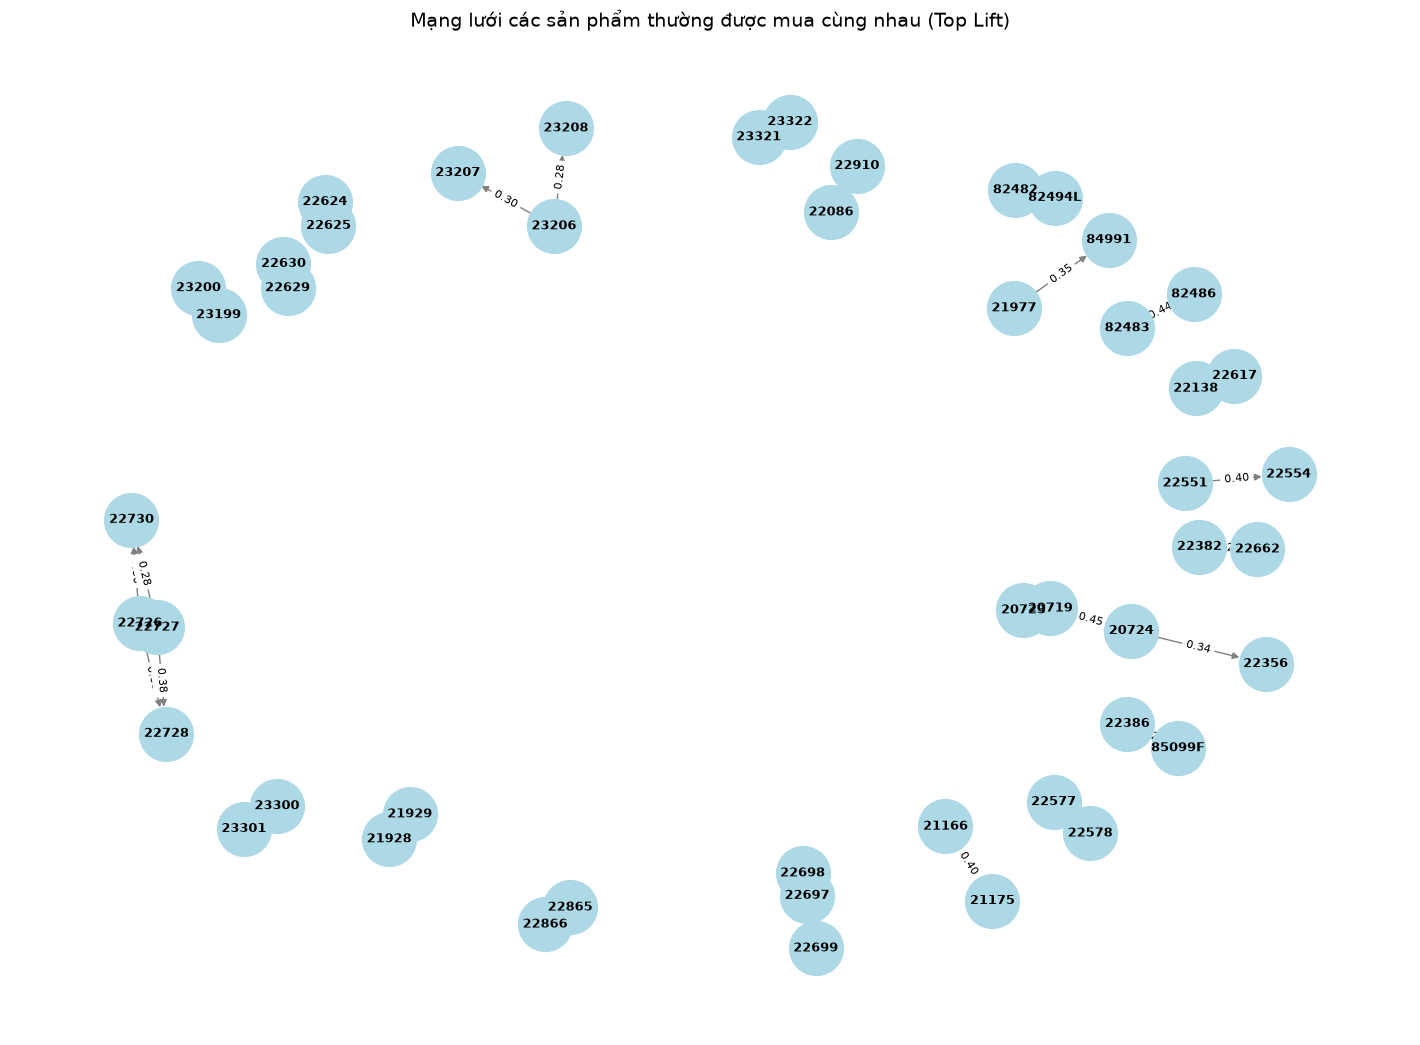

In [ ]:
!pip install networkx

import networkx as nx
import matplotlib.pyplot as plt

top_rules = rules_df.head(30)

G = nx.DiGraph()

for _, row in top_rules.iterrows():
    G.add_edge(row['ItemA'], row['ItemB'], weight=row['Lift(A→B)'], label=f"{row['Confidence(A→B)']:.2f}")

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.7, iterations=100)

nx.draw(G, pos, with_labels=True, node_size=1500, node_color='lightblue', font_size=9, font_weight='bold', edge_color='gray', arrows=True)

edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, label_pos=0.5)

plt.title("Mạng lưới các sản phẩm thường được mua cùng nhau (Top Lift)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# ĐÁNH GIÁ MÔ HÌNH KẾT HỢP USER-BASED + APRIORI TRÊN TEST_DF

import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.metrics.pairwise import cosine_similarity

required = {'CustomerID', 'StockCode', 'Quantity'}
for name, frame in [('train_df', train_df), ('test_df', test_df)]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} thiếu các cột: {sorted(missing)}")

if 'rules_df' not in globals():
    raise NameError("Chưa có rules_df. Hãy chạy cell tạo luật Apriori từ train_df trước.")

def _norm_customer_id(value):
    if pd.isna(value):
        return None
    try:
        number = float(value)
        if number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return str(value).strip()


def _norm_item(value):
    if pd.isna(value):
        return None
    return str(value).strip()

train_eval = train_df.dropna(subset=['CustomerID', 'StockCode']).copy()
train_eval['_user'] = train_eval['CustomerID'].map(_norm_customer_id)
train_eval['_item'] = train_eval['StockCode'].map(_norm_item)
train_eval = train_eval[
    (train_eval['Quantity'] > 0)
    & train_eval['_user'].notna()
    & train_eval['_item'].notna()
]

hybrid_user_item = train_eval.pivot_table(
    index='_user',
    columns='_item',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

if hybrid_user_item.empty:
    raise ValueError("Ma trận train rỗng; kiểm tra dữ liệu train_df.")

_user_similarity_values = cosine_similarity(hybrid_user_item)
hybrid_user_similarity = pd.DataFrame(
    _user_similarity_values,
    index=hybrid_user_item.index,
    columns=hybrid_user_item.index
)

needed_rule_cols = {'ItemA', 'ItemB'}
if not needed_rule_cols.issubset(rules_df.columns):
    raise ValueError(
        "rules_df cần có ItemA và ItemB. Hãy chạy cell Apriori trước."
    )

confidence_col = 'Confidence(A→B)'
if confidence_col not in rules_df.columns:
    confidence_candidates = [
        col for col in rules_df.columns
        if 'confidence' in str(col).lower() and 'a' in str(col).lower()
    ]
    if not confidence_candidates:
        raise ValueError(
            "Không tìm thấy cột Confidence(A→B) trong rules_df. "
            f"Các cột hiện có: {rules_df.columns.tolist()}"
        )
    confidence_col = confidence_candidates[0]

hybrid_rules = rules_df[['ItemA', 'ItemB', confidence_col]].copy()
hybrid_rules['ItemA'] = hybrid_rules['ItemA'].map(_norm_item)
hybrid_rules['ItemB'] = hybrid_rules['ItemB'].map(_norm_item)
hybrid_rules[confidence_col] = pd.to_numeric(
    hybrid_rules[confidence_col], errors='coerce'
)
hybrid_rules = hybrid_rules.dropna(subset=['ItemA', 'ItemB', confidence_col])

def _user_based_scores(customer_id, n_neighbors=3):
    """Tính điểm sản phẩm từ 3 người dùng tương đồng nhất trong train."""
    if customer_id not in hybrid_user_item.index:
        return {}

    similarities = hybrid_user_similarity.loc[customer_id].drop(
        labels=[customer_id], errors='ignore'
    )
    similarities = similarities[similarities > 0].nlargest(n_neighbors)
    if similarities.empty:
        return {}

    bought_items = set(
        hybrid_user_item.columns[hybrid_user_item.loc[customer_id] > 0]
    )
    scores = defaultdict(float)

    for neighbor_id, similarity_score in similarities.items():
        neighbor_row = hybrid_user_item.loc[neighbor_id]
        candidate_items = neighbor_row[neighbor_row > 0]
        for item, quantity in candidate_items.items():
            if item not in bought_items:
                scores[item] += float(similarity_score) * float(quantity)

    return dict(scores)


def _apriori_scores(customer_id):
    """Dùng luật ItemA -> ItemB và Confidence(A→B) từ rules_df."""
    if customer_id not in hybrid_user_item.index:
        return {}

    bought_items = set(
        hybrid_user_item.columns[hybrid_user_item.loc[customer_id] > 0]
    )
    scores = defaultdict(float)

    for _, rule in hybrid_rules.iterrows():
        item_a = rule['ItemA']
        item_b = rule['ItemB']
        confidence = float(rule[confidence_col])

        if item_a in bought_items and item_b not in bought_items:
            scores[item_b] += confidence

    return dict(scores)


def _hybrid_recommend(customer_id, top_n=10, alpha=0.5):
    """Kết hợp điểm giống code hiện tại: alpha*UserCF + (1-alpha)*Apriori."""
    user_scores = _user_based_scores(customer_id, n_neighbors=3)
    apriori_scores = _apriori_scores(customer_id)
    combined = defaultdict(float)

    for item, score in user_scores.items():
        combined[item] += alpha * score
    for item, score in apriori_scores.items():
        combined[item] += (1 - alpha) * score

    ranked = sorted(combined.items(), key=lambda pair: pair[1], reverse=True)
    return [item for item, score in ranked[:top_n]]

test_eval = test_df.dropna(subset=['CustomerID', 'StockCode']).copy()
test_eval['_user'] = test_eval['CustomerID'].map(_norm_customer_id)
test_eval['_item'] = test_eval['StockCode'].map(_norm_item)
test_eval = test_eval[
    (test_eval['Quantity'] > 0)
    & test_eval['_user'].notna()
    & test_eval['_item'].notna()
]

actual_test_all = test_eval.groupby('_user')['_item'].agg(set).to_dict()
test_users = set(actual_test_all)
train_users = set(hybrid_user_item.index)
known_test_users = test_users & train_users
cold_start_users = test_users - train_users

actual_new_items = {}
for user in known_test_users:
    already_bought = set(
        hybrid_user_item.columns[hybrid_user_item.loc[user] > 0]
    )
    unseen_in_test = actual_test_all[user] - already_bought
    if unseen_in_test:
        actual_new_items[user] = unseen_in_test

if not actual_new_items:
    raise ValueError(
        "Không có sản phẩm mới với khách hàng trong test_df để chấm điểm. "
        "Hãy kiểm tra cách chia thời gian hoặc cân nhắc đánh giá cả sản phẩm mua lặp lại."
    )

def _evaluate_at_k(k):
    precision_list, recall_list, f1_list = [], [], []
    hit_rate_list, ap_list, ndcg_list = [], [], []
    mismatch_rates = []
    recommendation_coverage = []

    for user, relevant_items in actual_new_items.items():
        recs = _hybrid_recommend(user, top_n=k, alpha=0.5)
        recs = list(dict.fromkeys(recs))[:k]
        hits_vector = [1 if item in relevant_items else 0 for item in recs]
        hit_count = sum(hits_vector)

        precision = hit_count / k
        recall = hit_count / len(relevant_items) if relevant_items else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        )
        hit_rate = 1.0 if hit_count > 0 else 0.0

        mismatch = (1 - hit_count / len(recs)) if recs else np.nan

        ap_total = 0.0
        hits_so_far = 0
        for rank, is_relevant in enumerate(hits_vector, start=1):
            if is_relevant:
                hits_so_far += 1
                ap_total += hits_so_far / rank
        ap = ap_total / min(len(relevant_items), k) if relevant_items else 0.0

        dcg = sum(
            rel / np.log2(rank + 1)
            for rank, rel in enumerate(hits_vector, start=1)
        )
        ideal_count = min(len(relevant_items), k)
        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_count + 1)
        )
        ndcg = dcg / idcg if idcg else 0.0

        precision_list.append(precision)
        recall_list.append(recall)
        f1_list.append(f1)
        hit_rate_list.append(hit_rate)
        ap_list.append(ap)
        ndcg_list.append(ndcg)
        mismatch_rates.append(mismatch)
        recommendation_coverage.append(1 if recs else 0)

    return {
        'K': k,
        'Precision@K (%)': np.mean(precision_list) * 100,
        'Recall@K (%)': np.mean(recall_list) * 100,
        'F1-score@K (%)': np.mean(f1_list) * 100,
        'Hit Rate@K (%)': np.mean(hit_rate_list) * 100,
        'MAP@K (%)': np.mean(ap_list) * 100,
        'NDCG@K (%)': np.mean(ndcg_list) * 100,
        'Tỷ lệ gợi ý không khớp (%)': np.nanmean(mismatch_rates) * 100,
        'User có gợi ý / user được chấm (%)': np.mean(recommendation_coverage) * 100,
        'Số user được chấm': len(actual_new_items),
    }

K_VALUES = (5, 10)
hybrid_metrics_df = pd.DataFrame([_evaluate_at_k(k) for k in K_VALUES])

n_test_users = len(test_users)
summary_coverage_df = pd.DataFrame([{
    'Tổng user trong test': n_test_users,
    'User có lịch sử trong train': len(known_test_users),
    'User cold-start (không có trong train)': len(cold_start_users),
    'Tỷ lệ user test có lịch sử train (%)': (
        100 * len(known_test_users) / n_test_users if n_test_users else 0
    ),
    'User có sản phẩm mới để đánh giá': len(actual_new_items),
    'User bị loại do không có sản phẩm mới': len(known_test_users) - len(actual_new_items),
}])

print('=== ĐỘ BAO PHỦ TEST ===')
display(summary_coverage_df)

print('=== ĐÁNH GIÁ MÔ HÌNH KẾT HỢP USER-BASED + APRIORI ===')
display(hybrid_metrics_df.round(2))
